# Đánh giá LSTM dự báo PM2.5 và so với mô hình đối chứng

Notebook này đánh giá mô hình do `training/train_lstm.py` huấn luyện, theo mục "Yêu cầu về phương pháp" trong `CLAUDE.md`:

- Chia theo thời gian 70/15/15 như notebook `01_phan_tich_chuoi.ipynb`, không xáo trộn; `MinMaxScaler` chỉ fit trên train.
- Cấu hình LSTM (đích mức PM2.5 hay sai phân lag 24; có hay không có nhiệt độ + độ ẩm) **chỉ chọn theo MAE trên validation**. Tập test chỉ dùng ở phần 3, với cấu hình đã chọn, không chỉnh gì sau khi xem kết quả test.
- Mô hình được đánh giá là **đúng file `.tflite` + `scaler.json`** sẽ chép lên Pi, chạy qua `aiot.forecast.load_predictor` (cùng code suy luận với Pi), không phải mô hình Keras.
- Đối chứng: persistence, seasonal naive (cùng giờ hôm qua) và hồi quy Ridge trên đặc trưng trễ.
- Chỉ số theo từng horizon 1–6 giờ: MAE, RMSE, độ chính xác nhóm AQI (`aiot.aqi.classify`, US EPA 2024) và độ nhạy với sự kiện vượt ngưỡng (giá trị thật ≥ 55,5 µg/m³, tức nhóm "Xấu" trở lên).

**Dữ liệu:** `training/data/hanoi_openmeteo.csv` là PM2.5 **mô hình CAMS** (không phải số đo trạm) và thời tiết ERA5 cho Hà Nội, xem `training/data/SOURCE.md`. Đây là kết quả trên dữ liệu công khai; **kết quả trên dữ liệu Pi chưa có** (Pi mới thu vài ngày).

Chạy lại: `.venv/Scripts/python -m training.train_lstm`, rồi `.venv/Scripts/jupyter nbconvert --to notebook --execute --inplace training/02_danh_gia.ipynb`.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "training").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from aiot import forecast as fc
from training import train_lstm as tl
from training.evaluate import EXCEEDANCE_INDEX, aqi_index, evaluate

plt.rcParams.update({"figure.dpi": 72, "figure.figsize": (9, 3.2), "axes.grid": True})
pd.set_option("display.precision", 3)
MODELS = ROOT / "models"
summary = json.loads((MODELS / "train_summary.json").read_text(encoding="utf-8"))
H = [f"h{k}" for k in range(1, 7)]

df = tl.load_frame()
parts, windows = tl.split_windows(df)
pd.DataFrame(summary["split"]).T

,start,end,hours,windows
train,2022-08-04 07:00:00+07:00,2025-07-28 06:00:00+07:00,26136,26107
val,2025-07-28 07:00:00+07:00,2026-03-18 15:00:00+07:00,5601,5572
test,2026-03-18 16:00:00+07:00,2026-11-06 23:00:00+07:00,5600,5571


## 1. Chọn cấu hình LSTM trên tập validation

Bốn cấu hình được huấn luyện với cùng siêu tham số (LSTM 1 lớp, early stopping theo loss validation, seed cố định). Bảng dưới là MAE (µg/m³) trên validation, đọc từ `models/train_summary.json` do `train_lstm.py` ghi; cấu hình có MAE trung bình 6 horizon nhỏ nhất được chọn.

In [2]:
print("Siêu tham số:", summary["hyper"], "| TensorFlow", summary["tensorflow"], "| seed", summary["seed"])
rows = {c["name"]: c["val"]["mae"] + [c["val_mae_mean"], c["best_epoch"], c["train_seconds"]]
        for c in summary["configs"]}
val_table = pd.DataFrame(rows, index=H + ["TB", "epoch tốt nhất", "giây"]).T
for name, m in summary["val_baselines"].items():
    val_table.loc[f"(đối chứng) {name}"] = m["mae"] + [np.mean(m["mae"]), np.nan, np.nan]
print("Cấu hình được chọn:", summary["chosen"], "| tổng thời gian huấn luyện", summary["total_seconds"], "s")
val_table

Siêu tham số: {'units': 64, 'epochs': 70, 'patience': 5, 'batch': 256, 'loss': 'mse', 'optimizer': 'adam 1e-3'} | TensorFlow 2.21.0 | seed 42
Cấu hình được chọn: pm25_thoitiet | tổng thời gian huấn luyện 653.9 s


,h1,h2,h3,h4,h5,h6,TB,epoch tốt nhất,giây
pm25_thoitiet,3.523,6.478,9.108,11.009,12.645,13.944,9.451,52.0,185.9
pm25_khong_thoitiet,3.688,6.605,9.234,11.239,12.905,14.137,9.635,70.0,161.7
diff24_thoitiet,5.260,7.382,9.660,11.447,12.909,14.058,10.119,70.0,160.0
diff24_khong_thoitiet,5.987,7.698,9.925,11.775,13.330,14.729,10.574,58.0,140.9
(đối chứng) persistence,5.135,9.388,13.085,16.289,19.134,21.595,14.104,NaN,NaN
(đối chứng) seasonal_naive,21.343,21.331,21.322,21.315,21.311,21.308,21.322,NaN,NaN
(đối chứng) ridge,3.746,7.109,9.894,12.103,13.759,14.963,10.262,NaN,NaN


## 2. Kiểm tra file TFLite

Xuất với batch cố định 1, chỉ op có sẵn của TFLite (không Flex). So sánh đầu ra Keras và `.tflite` trên 20 cửa sổ validation (đơn vị chuẩn hoá của mô hình, yêu cầu < 1e-3).

In [3]:
import tensorflow as tf

spec_raw = json.loads((MODELS / "scaler.json").read_text(encoding="utf-8"))
keras_model = tf.keras.models.load_model(MODELS / "pm25_lstm.keras")
X_val_s, _ = tl.to_model_space(spec_raw, windows["val"][0])
diff = tl.parity(keras_model, MODELS / "pm25_lstm.tflite", X_val_s, n=20)
tfl_bytes = (MODELS / "pm25_lstm.tflite").read_bytes()
print("scaler.json:", {k: spec_raw[k] for k in ("model_version", "features", "target", "n_in", "n_out")})
print(f"Lệch tuyệt đối lớn nhất Keras/TFLite trên 20 cửa sổ: {diff:.2e} (đạt < 1e-3: {diff < 1e-3})")
print(f"Có op Flex: {b'Flex' in tfl_bytes}")
print(f"pm25_lstm.tflite: {len(tfl_bytes)} byte; scaler.json: {(MODELS / 'scaler.json').stat().st_size} byte")

scaler.json: {'model_version': 'pm25_lstm-2026-11-07-pm25_thoitiet', 'features': ['pm25', 'temp', 'hum', 'hour_sin', 'hour_cos'], 'target': {'kind': 'pm25', 'min': 0.3, 'max': 232.8}, 'n_in': 24, 'n_out': 6}
Lệch tuyệt đối lớn nhất Keras/TFLite trên 20 cửa sổ: 2.38e-07 (đạt < 1e-3: True)
Có op Flex: False
pm25_lstm.tflite: 82436 byte; scaler.json: 430 byte


C:\Users\nviquang\Documents\University\FourthYear\IoT\BTL\Chapter12\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 3. Đánh giá trên tập test (một lần, cấu hình đã chọn)

LSTM chạy qua `load_predictor` với từng cửa sổ (dict 24 giờ như trên Pi). Ridge được fit trên train, `alpha` chọn theo MAE validation.

In [4]:
X_te, y_te, t_te = windows["test"]
predict = fc.load_predictor(MODELS / "pm25_lstm.tflite", MODELS / "scaler.json")
assert predict is not None
t0 = time.perf_counter()
lstm_pred = np.array([predict(f) for f in tl.window_features(X_te)])
ms = (time.perf_counter() - t0) * 1000 / len(X_te)
ridge, alpha, _ = tl.fit_ridge(windows)
preds = {
    "LSTM": lstm_pred,
    "persistence": np.repeat(X_te[:, -1:, 0], 6, axis=1),
    "seasonal_naive": tl.same_hour_yesterday(X_te),
    f"ridge (alpha={alpha:g})": ridge.predict(tl.lag_features(X_te)),
}
results = {name: evaluate(y_te, p) for name, p in preds.items()}
print(f"Tập test: {len(X_te)} cửa sổ, đích từ {t_te[0]} đến {t_te[-1]}")
print(f"Suy luận TFLite trên laptop: {ms:.2f} ms/cửa sổ (gồm chuẩn hoá); thời gian trên Pi đo sau khi triển khai")
events = (aqi_index(y_te) >= EXCEEDANCE_INDEX).sum(axis=0)
print("Số sự kiện vượt ngưỡng (thật >= 55,5 µg/m³) theo horizon:", list(map(int, events)))

def table(key):
    return pd.DataFrame({n: r[key] for n, r in results.items()}, index=H).T

mae, rmse = table("mae"), table("rmse")
mae["TB"], rmse["TB"] = mae.mean(axis=1), rmse.mean(axis=1)
print("\nMAE (µg/m³)"); print(mae.round(3).to_string())
print("\nRMSE (µg/m³)"); print(rmse.round(3).to_string())
print("\nĐộ chính xác nhóm AQI"); print(table("aqi_accuracy").round(3).to_string())
print("\nĐộ nhạy vượt ngưỡng (>= 55,5 µg/m³)"); print(table("exceedance_recall").astype(float).round(3).to_string())

Tập test: 5571 cửa sổ, đích từ 2026-03-19 16:00:00+07:00 đến 2026-11-06 18:00:00+07:00
Suy luận TFLite trên laptop: 0.13 ms/cửa sổ (gồm chuẩn hoá); thời gian trên Pi đo sau khi triển khai
Số sự kiện vượt ngưỡng (thật >= 55,5 µg/m³) theo horizon: [1520, 1520, 1520, 1520, 1520, 1520]

MAE (µg/m³)
                        h1      h2      h3      h4      h5      h6      TB
LSTM                 3.940   6.809   9.625  11.620  13.237  14.328   9.927
persistence          5.034   9.143  12.716  15.826  18.497  20.798  13.669
seasonal_naive      17.325  17.324  17.324  17.324  17.323  17.323  17.324
ridge (alpha=0.01)   3.852   7.180   9.856  11.937  13.343  14.342  10.085

RMSE (µg/m³)
                        h1      h2      h3      h4      h5      h6      TB
LSTM                 6.857  10.896  14.727  17.490  19.662  21.126  15.126
persistence          8.633  15.090  20.411  24.768  28.349  31.318  21.428
seasonal_naive      26.013  26.012  26.012  26.012  26.012  26.012  26.012
ridge (alpha=0.

In [5]:
# Kết luận theo tiêu chí trong CLAUDE.md: "LSTM vượt persistence ở horizon >= 2 giờ"
better = {h: results["LSTM"]["mae"][h - 1] < results["persistence"]["mae"][h - 1] for h in range(1, 7)}
for h in range(1, 7):
    l, p = results["LSTM"]["mae"][h - 1], results["persistence"]["mae"][h - 1]
    print(f"h{h}: LSTM {l:.3f} vs persistence {p:.3f} -> {'LSTM tốt hơn' if better[h] else 'LSTM KHÔNG tốt hơn'} ({(p - l) / p * 100:+.1f}%)")
passed = all(better[h] for h in range(2, 7))
print("\nĐạt tiêu chí 'LSTM vượt persistence (MAE) ở mọi horizon >= 2 giờ' trên dữ liệu công khai:", passed)
for other in [n for n in results if n not in ("LSTM", "persistence")]:
    wins = [h for h in range(1, 7) if results["LSTM"]["mae"][h - 1] < results[other]["mae"][h - 1]]
    print(f"LSTM có MAE nhỏ hơn {other} ở các horizon: {wins}")

h1: LSTM 3.940 vs persistence 5.034 -> LSTM tốt hơn (+21.7%)
h2: LSTM 6.809 vs persistence 9.143 -> LSTM tốt hơn (+25.5%)
h3: LSTM 9.625 vs persistence 12.716 -> LSTM tốt hơn (+24.3%)
h4: LSTM 11.620 vs persistence 15.826 -> LSTM tốt hơn (+26.6%)
h5: LSTM 13.237 vs persistence 18.497 -> LSTM tốt hơn (+28.4%)
h6: LSTM 14.328 vs persistence 20.798 -> LSTM tốt hơn (+31.1%)

Đạt tiêu chí 'LSTM vượt persistence (MAE) ở mọi horizon >= 2 giờ' trên dữ liệu công khai: True
LSTM có MAE nhỏ hơn seasonal_naive ở các horizon: [1, 2, 3, 4, 5, 6]
LSTM có MAE nhỏ hơn ridge (alpha=0.01) ở các horizon: [2, 3, 4, 5, 6]


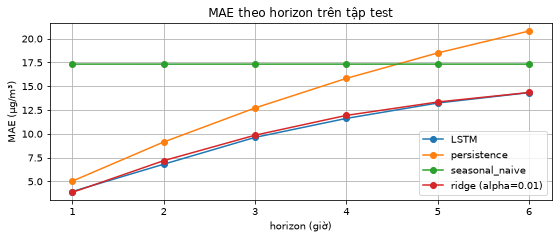

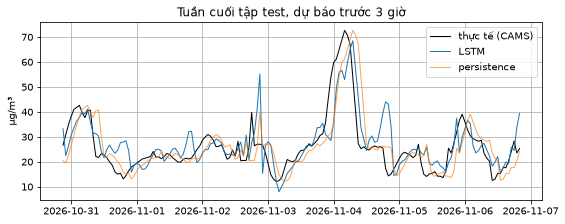

In [6]:
fig, ax = plt.subplots()
for name in mae.index:
    ax.plot(range(1, 7), mae.loc[name, H], marker="o", label=name)
ax.set_xlabel("horizon (giờ)"); ax.set_ylabel("MAE (µg/m³)"); ax.set_title("MAE theo horizon trên tập test")
ax.legend(); plt.show()

# Một tuần cuối tập test, horizon 3 giờ
k, n = 3, 7 * 24
t = t_te[-n:] + pd.Timedelta(hours=k - 1)
fig, ax = plt.subplots()
ax.plot(t, y_te[-n:, k - 1], color="k", lw=1, label="thực tế (CAMS)")
ax.plot(t, lstm_pred[-n:, k - 1], lw=1, label="LSTM")
ax.plot(t, preds["persistence"][-n:, k - 1], lw=1, alpha=0.7, label="persistence")
ax.set_ylabel("µg/m³"); ax.set_title(f"Tuần cuối tập test, dự báo trước {k} giờ"); ax.legend(); plt.show()

## 4. Kết luận (từ các số in ở trên)

**Chọn cấu hình (validation):** `pm25_thoitiet` (đích là mức PM2.5, đầu vào PM2.5 + nhiệt độ + độ ẩm + sin/cos giờ) có MAE validation trung bình nhỏ nhất, 9,451 µg/m³, so với 9,635 (không thời tiết), 10,119 (diff24 có thời tiết) và 10,574 (diff24 không thời tiết). Đích sai phân lag 24 kém hơn ở mọi cấu hình, nhất là horizon 1 (5,26–5,99 so với 3,52–3,69), nên không dùng. Thêm nhiệt độ và độ ẩm giúp ít (khoảng 0,18 µg/m³ MAE trung bình).

**Kiểm tra TFLite:** Keras và `.tflite` lệch tối đa 2,38e-07 trên 20 cửa sổ (yêu cầu < 1e-3), không có op Flex; file `.tflite` 82 436 byte.

**Tập test (5 571 cửa sổ, 19/03/2026 – 06/11/2026, đánh giá một lần):**

- **LSTM vượt persistence ở mọi horizon, kể cả mọi horizon ≥ 2 giờ** trên dữ liệu công khai: MAE 6,81 so với 9,14 µg/m³ ở h2 (giảm 25,5%) đến 14,33 so với 20,80 ở h6 (giảm 31,1%). RMSE, độ chính xác nhóm AQI (0,806 so với 0,743 ở h2; 0,602 so với 0,495 ở h6) và độ nhạy vượt ngưỡng (0,855 so với 0,803 ở h2; 0,688 so với 0,533 ở h6) cũng tốt hơn persistence ở mọi horizon.
- Seasonal naive kém nhất (MAE 17,32 ở mọi horizon), kém cả persistence ở h1–h4.
- **LSTM chỉ hơn Ridge trên đặc trưng trễ rất ít:** MAE trung bình 9,93 so với 10,09 µg/m³; Ridge tốt hơn ở h1 (3,85 so với 3,94) và gần bằng ở h5–h6 (13,24/13,34; 14,33/14,34); Ridge có độ chính xác nhóm AQI ở h5–h6 và độ nhạy vượt ngưỡng ở h3–h5 nhỉnh hơn LSTM. Nghĩa là phần lớn lợi ích đến từ việc dùng 24 giờ lịch sử, không phải riêng từ kiến trúc LSTM; một mô hình tuyến tính đơn giản cũng đạt gần như vậy.
- Độ nhạy vượt ngưỡng giảm theo horizon (0,92 ở h1 xuống 0,69 ở h6): dự báo 6 giờ bỏ lỡ khoảng 31% số giờ "Xấu" trở lên, nên luật "Chủ động" không thể thay luật theo số đo hiện tại.

**Kết luận theo tiêu chí trong `CLAUDE.md`:** trên dữ liệu công khai (CAMS), LSTM **đạt** "vượt persistence ở horizon ≥ 2 giờ". Đây **chưa phải** điều kiện để đưa lên Pi: tiêu chí phải được kiểm lại trên dữ liệu đo của trạm. Tới lúc đó sản phẩm vẫn dùng mô hình đối chứng.

## Lưu ý và việc còn lại

- **Dữ liệu là mô hình CAMS, không phải số đo trạm.** CAMS là trường mô hình trên lưới thô, mượt hơn số đo cảm biến thật; dao động ngắn hạn và sự kiện cục bộ (đun nấu, khói trong nhà) không có trong dữ liệu này. Kết quả ở đây chỉ cho thấy phương pháp chạy đúng và mô hình học được động thái của chuỗi CAMS.
- **Chưa đánh giá trên dữ liệu Pi.** Theo `CLAUDE.md`, mô hình chỉ được chép lên Pi và dùng cho sản phẩm khi vượt persistence ở horizon ≥ 2 giờ **trên dữ liệu của trạm** (cảm biến PMS7003 trong nhà). Khi Pi có đủ dữ liệu (ít nhất vài tuần), chạy lại đánh giá với `training/export_hourly.py` và báo cáo riêng.
- **Đối chứng Open-Meteo Air Quality chưa so được.** Ở đây CAMS chính là giá trị thật, nên so dự báo CAMS với chính nó không có ý nghĩa. So sánh này chỉ làm được khi có số đo của Pi.
- **SARIMA không chạy.** Đánh giá cuốn chiếu trên hàng nghìn cửa sổ test (mỗi cửa sổ fit lại hoặc cập nhật trạng thái SARIMA mùa 24) quá chậm trên laptop; dùng hồi quy Ridge trên đặc trưng trễ làm đối chứng thống kê thay thế.
- Hiệu chỉnh độ ẩm: độ ẩm cao ở Hà Nội có thể làm PMS7003 đọc cao hơn thực tế; khi đánh giá trên Pi cần đối chiếu trạm công khai.